In [3]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_excel("Analytics_mindset_case_study_solutions_Trinas_Trinkets.xlsx")


In [4]:
from sklearn import linear_model
df_clean = df.copy()

anzahlduplikate = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()
print(f"Es gibt {anzahlduplikate} duplikate")
# Keine Duplikate

df_clean = df_clean.dropna().reset_index(drop = True)
# 29 Zeilen mit min. 1 Fehlenden Wert


print(df_clean['Revenue'].describe().round(2))

vorher = df_clean.shape[0]
print(vorher)

df_clean = df_clean.loc[(df_clean['Revenue'] > 0) & 
                        (df_clean['Quantity'] > 0) & 
                        (df_clean['UnitPrice'] > 0)]
# Umsätze unter 0 & Qunatity unter 0 & Unitprice unter 0 werden ausgefiltert 
# Aus Sicherheitsgründen damit keine Fehler enthalten sind

nachher = df_clean.shape[0]
print(nachher)

differenz = vorher - nachher 
print(f"Die Differenz liegt bei: {differenz}")


q_high = df_clean['Revenue'].quantile(0.999)# Oder 0.9999 absprache halten
print(df_clean['Revenue'].quantile(0.999))

df_clean = df_clean.loc[df_clean['Revenue'] < q_high].reset_index(drop=True)
# Damit werden die oberen 0,01% gelöscht um mutmaßliche Falsch abbuchungen zu eliminieren


year = df_clean[['InvoiceYear']].value_counts()
print(year)
# Jahresdiffernez an Daten


print(df_clean['Revenue'].describe().round(2))
# Zu sehen das die Standardabweichung bei Revenue wieder normal ist 
# Von 428 auf 40.45 gesunken 


print(df_clean['Revenue'].max())
# Maximal berücksichtigtes Revenue

Es gibt 0 duplikate
count    394800.00
mean         20.86
std         428.12
min     -168469.60
25%           4.35
50%          11.80
75%          19.80
max      168469.60
Name: Revenue, dtype: float64
394800
386325
Die Differenz liegt bei: 8475
855.5999999999999
InvoiceYear
2017           360756
2016            25181
Name: count, dtype: int64
count    385937.00
mean         20.18
std          40.45
min           0.06
25%           4.95
50%          12.48
75%          19.80
max         851.76
Name: Revenue, dtype: float64
851.76


In [5]:
df.info()
df_clean["InvoiceMonth"] = pd.to_datetime(df_clean["InvoiceDate"]).dt.month


<class 'pandas.DataFrame'>
RangeIndex: 394829 entries, 0 to 394828
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   TransactionID          394829 non-null  int64         
 1   InvoiceNo              394829 non-null  object        
 2   StockCode              394829 non-null  object        
 3   Quantity               394829 non-null  int64         
 4   UnitPrice              394829 non-null  float64       
 5   CustomerNumber         394829 non-null  int64         
 6   ZipCode                394829 non-null  int64         
 7   State                  394829 non-null  str           
 8   City                   394829 non-null  str           
 9   Revenue                394829 non-null  float64       
 10  SalesTaxOwed           394829 non-null  float64       
 11  InvoiceDate            394829 non-null  datetime64[us]
 12  InvoiceYear            394829 non-null  int64         


,State,InvoiceYear,InvoiceMonth,ActualPostTaxProfit,PostTaxProfitIfNexus
0,Arizona,2016,12,23326.32960,9525.068226
1,Arizona,2017,1,19134.95360,7835.000275
2,Arizona,2017,2,18474.09200,7505.652212
3,Arizona,2017,3,23290.90260,9549.978916
4,Arizona,2017,4,20690.38160,8543.191536
...,...,...,...,...,...
73,Wyoming,2017,8,1191.70430,1191.704300
74,Wyoming,2017,9,2588.56970,2588.569700
75,Wyoming,2017,10,2563.51595,2563.515950
76,Wyoming,2017,11,2683.37880,2683.378800


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[1479.73]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[18565.3]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[602.13]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[7599.67]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


c:\Users\yjewa_dkcbooz\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\Users\yjewa_dkcbooz\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[299.12]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[5523.68]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[170.93]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[3156.39]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


... (14 outputs left out)

<Axes: xlabel='State'>

Text(0.5, 0, 'State')

Text(0, 0.5, 'Profit after Tax')

Text(0.5, 1.0, 'Comparison between the prognosted actual profit and the profit if there was a nexus')

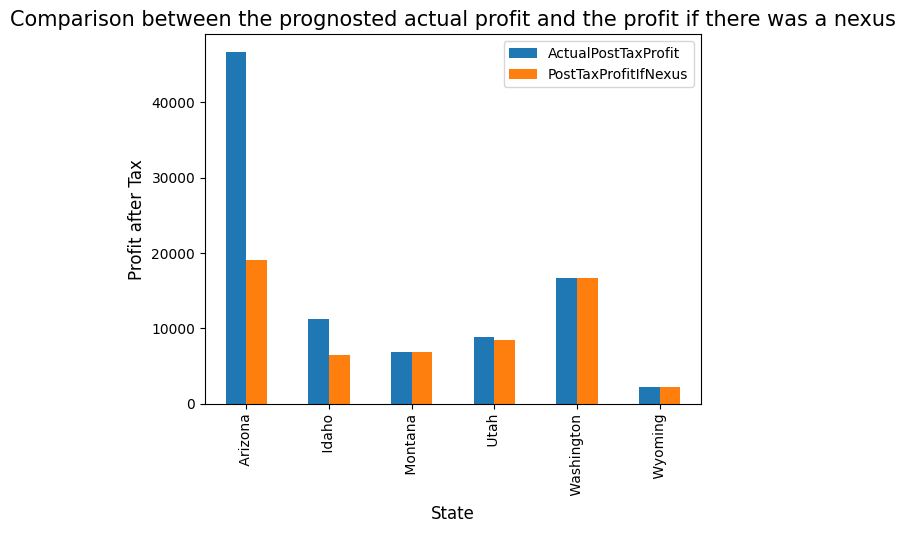

In [ ]:
df_clean["InvoiceMonth"] = pd.to_datetime(df_clean["InvoiceDate"]).dt.month #create a month variable for the linear Regression
# variables for the posttaxprofit
df_clean["PostTaxProfitIfNexus"] = df_clean["Profit"]-df_clean["SalesTaxNoNexus"] 
df_clean["ActualPostTaxProfit"] = df_clean["Profit"] - df_clean["SalesTaxOwed"]
# group dataframe for linear regression
df_grouped = df_clean.groupby(by=["State", "InvoiceYear", "InvoiceMonth"])[["ActualPostTaxProfit", "PostTaxProfitIfNexus"]].sum().reset_index()
df_grouped
growth_trends = []

# loop to predict the profit for all states
for state in df_grouped["State"].unique():
    df_state = df_grouped[df_grouped["State"] == state].copy()
    # add the time index
    df_state["time"] = range(len(df_state))

    if len(df_state) > 1:
        #predict profit for the actual profit
        model_actual = linear_model.LinearRegression()
        model_actual.fit(df_state[["time"]], df_state[["ActualPostTaxProfit"]])
        actual_post_tax_profit_growth = model_actual.coef_[0][0]
        
        #predict profit for the profitif there was a nexus
        model_ifnexus = linear_model.LinearRegression()
        model_ifnexus.fit(df_state[["time"]], df_state[["PostTaxProfitIfNexus"]])
        post_tax_profit_ifnexus_growth = model_ifnexus.coef_[0][0]


        # prediction for next month
        next_month_index = len(df_state)
        # save and append the predictions and the growth in the list
        growth_trends.append({
            "State": state,
            "ActualPostTaxProfit": model_actual.predict([[next_month_index]])[0][0],
            "ActualPostTaxProfitGrowth": actual_post_tax_profit_growth,
            "PostTaxProfitIfNexus": model_ifnexus.predict([[next_month_index]])[0][0],
            "PostTaxProfitIfNexusGrowth": post_tax_profit_ifnexus_growth
        })
# put list into dataframe
df_trends = pd.DataFrame(growth_trends)
df_trends

#create a multiple bar diagram to compare the profits 
df_trends.plot(kind="bar",x="State", y=["ActualPostTaxProfit", "PostTaxProfitIfNexus"])

plt.xlabel("State", fontsize =12)
plt.ylabel("Profit after Tax", fontsize = 12)
plt.title("Comparison between the prognosted actual profit and the profit if there was a nexus", fontsize =15)



                                             




In [ ]:

profit = df_clean.loc[(df_clean["InvoiceYear"] == 2017) & (df_clean["InvoiceMonth"] == 12) & (df_clean["State"].str.strip() == "Arizona"),["Profit"]]
realprofit = df_clean.loc[(df_clean["InvoiceYear"] == 2017) & (df_clean["InvoiceMonth"] == 12) & (df_clean["State"].str.strip() == "Arizona"),["RealProfit"]]
realprofit = realprofit.sum()
profit = profit.sum()
print(profit)
print(realprofit)

Profit    15712.8496
dtype: float64
RealProfit    15712.8496
dtype: float64
